# Tutorial 05a — Next-hour taxi-zone demand

**Question.** How many yellow-taxi pickups will occur in each Manhattan taxi zone next hour?

This tutorial connects the regression models from Modules 02–04 to a real spatiotemporal problem. The main modelling work is not a new algorithm: it is constructing useful, leakage-free features. We tune every model family on the validation period, freeze all choices, refit with the available development data, and inspect the test period only once.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `05 Transportation Applications I`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [112]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "05 Transportation Applications I"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/05 Transportation Applications I


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics.


In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [114]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [115]:
from pathlib import Path
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
warnings.filterwarnings("ignore"); np.random.seed(42)
FAMILY_COLORS={"Linear":"#4C78A8","Lasso":"#F58518","Ridge":"#B279A2","RF":"#54A24B","ANN":"#E45756"}
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold"})
required=["nyc_zone_hour.csv.gz","nyc_zone_features.csv","nyc_taxi_zones.geojson"]
assert all(Path(x).exists() for x in required), "Run from the 05 folder."

## 1. See the observations before modelling

Rows are complete zone–hour combinations, including zero-pickup hours. The map covers all 67 unique spatial units in the current official Manhattan taxi-zone boundary file. The harbour islands share LocationID 103 and are drawn as one multi-polygon feature. No zone was selected according to demand.

In [116]:
flow=pd.read_csv("nyc_zone_hour.csv.gz",parse_dates=["time"])
zones=pd.read_csv("nyc_zone_features.csv")
geo=json.load(open("nyc_taxi_zones.geojson"))
print("shape:",flow.shape,"time:",flow.time.min(),"to",flow.time.max())
display(flow.head()); display(flow.groupby("Borough").zone_id.nunique().rename("zones"))

shape: (96480, 5) time: 2024-01-01 00:00:00 to 2024-02-29 23:00:00


,time,zone_id,pickups,Borough,zone_name
0,2024-01-01,4,25,Manhattan,Alphabet City
1,2024-01-01,12,4,Manhattan,Battery Park
2,2024-01-01,13,15,Manhattan,Battery Park City
3,2024-01-01,24,27,Manhattan,Bloomingdale
4,2024-01-01,41,35,Manhattan,Central Harlem


Borough
Manhattan    67
Name: zones, dtype: int64

In [117]:
def polygons(feature):
    g=feature["geometry"]
    return g["coordinates"] if g["type"]=="MultiPolygon" else [g["coordinates"]]

def zone_map(values, title, cmap="YlGnBu", ax=None, colorbar=True):
    values=pd.Series(values)
    if ax is None: _,ax=plt.subplots(figsize=(8,7))
    norm=plt.Normalize(values.min(), values.max() if values.max()>values.min() else values.min()+1)
    for f in geo["features"]:
        zid=int(f["properties"]["LocationID"]); value=values.get(zid,np.nan)
        color="lightgrey" if pd.isna(value) else plt.colormaps[cmap](norm(value))
        for poly in polygons(f):
            ax.fill(*np.asarray(poly[0]).T,facecolor=color,edgecolor="white",linewidth=.45)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    if colorbar: plt.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=ax,shrink=.7)
    return ax

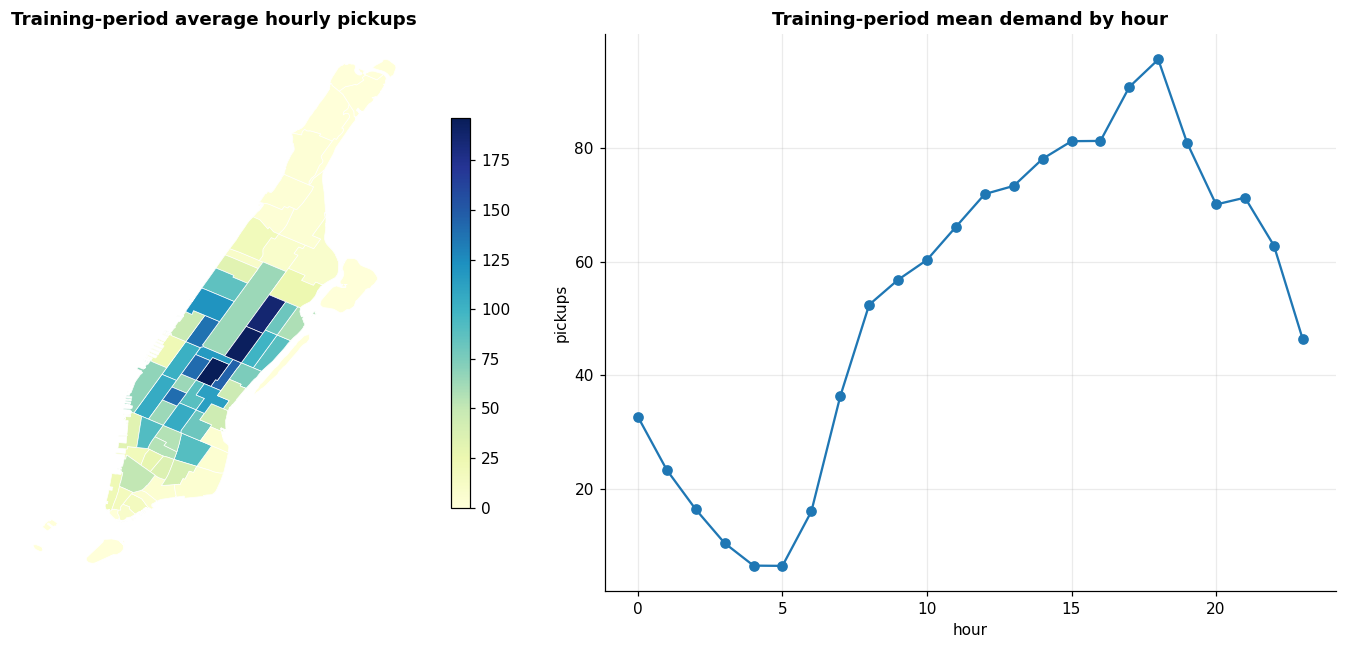

In [118]:
fig,ax=plt.subplots(1,2,figsize=(14,6))
descriptive=flow[flow.time<"2024-02-10"]  # training period only
avg=descriptive.groupby("zone_id").pickups.mean()
zone_map(avg,"Training-period average hourly pickups",ax=ax[0])
hourly=descriptive.assign(hour=descriptive.time.dt.hour).groupby("hour").pickups.mean()
ax[1].plot(hourly.index,hourly.values,marker="o"); ax[1].set(title="Training-period mean demand by hour",xlabel="hour",ylabel="pickups"); ax[1].grid(alpha=.25)
plt.tight_layout()

## 2. Convert time into supervised-learning rows

For a target hour $t$, we use only information that would already be available:

- closeness: $t-1,t-2,t-3$;
- daily period: $t-24$;
- weekly trend: $t-168$;
- cyclic calendar variables;
- static zone context.

The 168-hour lag necessarily removes the first week. `shift` is performed **within each zone**, preventing values from a different zone from entering the row.

In [119]:
d=flow.sort_values(["zone_id","time"]).copy()
for lag in [1,2,3,24,168]: d[f"lag_{lag}"]=d.groupby("zone_id").pickups.shift(lag)
d["hour_sin"]=np.sin(2*np.pi*d.time.dt.hour/24); d["hour_cos"]=np.cos(2*np.pi*d.time.dt.hour/24)
d["dow_sin"]=np.sin(2*np.pi*d.time.dt.dayofweek/7); d["dow_cos"]=np.cos(2*np.pi*d.time.dt.dayofweek/7)
d["weekend"]=(d.time.dt.dayofweek>=5).astype(int)
d=d.merge(zones[["LocationID","population_density","employment_density","poi_total"]],left_on="zone_id",right_on="LocationID").dropna().reset_index(drop=True)
feature_sets={
 "recent only":["lag_1","lag_2","lag_3"],
 "+ daily/weekly":["lag_1","lag_2","lag_3","lag_24","lag_168"],
 "+ calendar/context":["lag_1","lag_2","lag_3","lag_24","lag_168","hour_sin","hour_cos","dow_sin","dow_cos","weekend","population_density","employment_density","poi_total"]}
train = d.time < pd.Timestamp("2024-02-10")
valid = d.time.between("2024-02-10", "2024-02-20", inclusive="left")
test = d.time >= pd.Timestamp("2024-02-20")

all_features = feature_sets["+ calendar/context"]
X_train = d.loc[train, all_features].to_numpy()
y_train = d.loc[train, "pickups"].to_numpy()
X_valid = d.loc[valid, all_features].to_numpy()
y_valid = d.loc[valid, "pickups"].to_numpy()
X_test = d.loc[test, all_features].to_numpy()
y_test = d.loc[test, "pickups"].to_numpy()

print("Using the complete feature set for this shape check:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("Each X row has", X_train.shape[1], "features; each y value is next-hour pickups.")

assert d.loc[train, "time"].max() < d.loc[valid, "time"].min()
assert d.loc[valid, "time"].max() < d.loc[test, "time"].min()

Using the complete feature set for this shape check:
X_train: (53064, 13) y_train: (53064,)
X_valid: (16080, 13) y_valid: (16080,)
X_test : (16080, 13) y_test : (16080,)
Each X row has 13 features; each y value is next-hour pickups.


## 3. Validation sensitivity, one small decision at a time

Linear regression has no regularisation hyperparameter, so its sensitivity analysis compares feature structures. Lasso and Ridge vary `alpha`; the forest varies depth; the ANN varies hidden width. These grids are intentionally small: the goal is to understand sensitivity rather than run an expensive search.

In [120]:
def metrics(y,p):
    return {"MAE":mean_absolute_error(y,p),"RMSE":mean_squared_error(y,p)**.5,
            "R2":r2_score(y,p),"WAPE":np.abs(y-p).sum()/np.maximum(np.abs(y).sum(),1)}

,family,setting,validation_MAE
12,ANN,ANN | width=16,10.594727
13,ANN,ANN | width=32,10.610330
3,Lasso,Lasso | alpha=0.01,10.646931
4,Lasso,Lasso | alpha=0.1,10.678224
5,Lasso,Lasso | alpha=1.0,11.004106
2,Linear,Linear | + calendar/context,10.644018
1,Linear,Linear | + daily/weekly,10.717431
0,Linear,Linear | recent only,14.379945
11,RF,RF | depth=None,10.148309
10,RF,RF | depth=14,10.151745


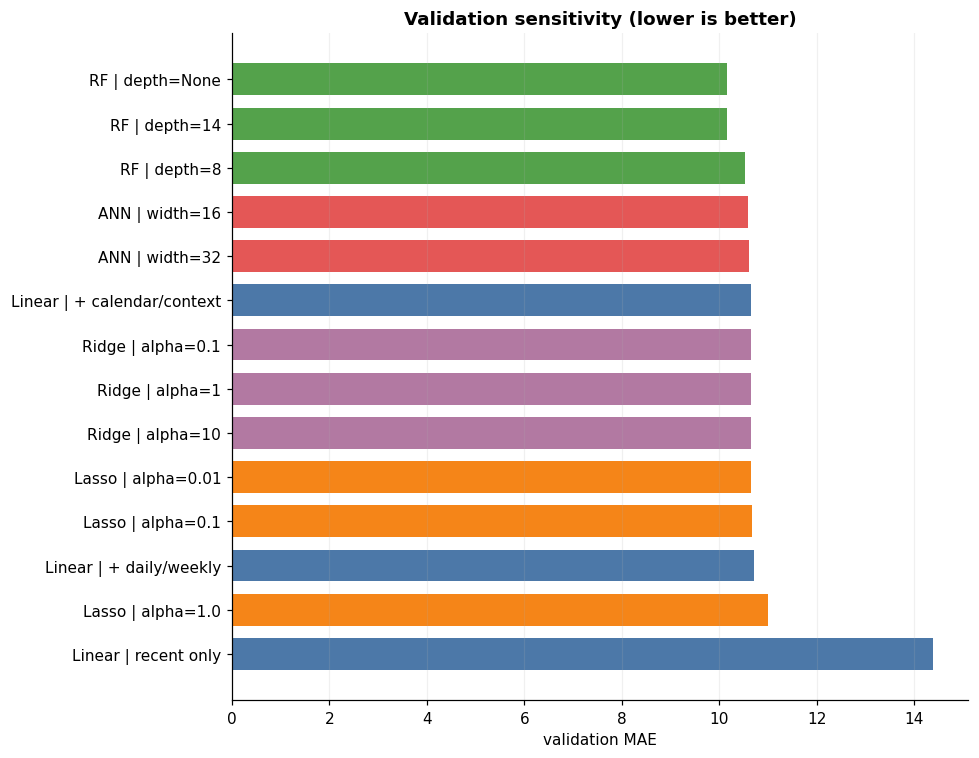

In [121]:
y=d.pickups.to_numpy(); full=feature_sets["+ calendar/context"]
records=[]; # StandardScaler is used only inside penalised/neural model pipelines.
# It rescales X features with different units; y, predictions, MAE, and RMSE
# remain in the original traffic-flow units shown in the result tables.
candidates={}
for label,cols in feature_sets.items(): candidates[f"Linear | {label}"]=(LinearRegression(),cols)
for a in [.01,.1,1.0]: candidates[f"Lasso | alpha={a}"]=(make_pipeline(StandardScaler(),Lasso(alpha=a,max_iter=3000)),full)
for a in [.1,1,10]: candidates[f"Ridge | alpha={a}"]=(make_pipeline(StandardScaler(),Ridge(alpha=a)),full)
for depth in [8,14,None]: candidates[f"RF | depth={depth}"]=(RandomForestRegressor(n_estimators=60,max_depth=depth,min_samples_leaf=3,max_samples=.6,n_jobs=-1,random_state=42),full)
for width in [16,32]: candidates[f"ANN | width={width}"]=(make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(width,),max_iter=100,early_stopping=True,random_state=42)),full)
for name,(model,cols) in candidates.items():
    model.fit(d.loc[train,cols],y[train]); p=np.clip(model.predict(d.loc[valid,cols]),0,None)
    family=name.split(" | ")[0]; records.append({"family":family,"setting":name,"validation_MAE":mean_absolute_error(y[valid],p)})
validation=pd.DataFrame(records).sort_values(["family","validation_MAE"])
display(validation)
pv=validation.sort_values("validation_MAE",ascending=False); fig,ax=plt.subplots(figsize=(9,7)); ax.barh(pv.setting,pv.validation_MAE,height=.72,color=pv.family.map(FAMILY_COLORS)); ax.set(xlabel="validation MAE",title="Validation sensitivity (lower is better)"); ax.grid(axis="x",alpha=.18); plt.tight_layout()

## 4. Freeze each family, then evaluate all families on test

Validation is used to select the best configuration **within each family**. We then refit that frozen configuration on train + validation. Test is not used to choose a winner: it provides one fair final comparison of all tuned model families.

,family,setting,validation_MAE
12,ANN,ANN | width=16,10.594727
3,Lasso,Lasso | alpha=0.01,10.646931
2,Linear,Linear | + calendar/context,10.644018
11,RF,RF | depth=None,10.148309
6,Ridge,Ridge | alpha=0.1,10.644026


,model,MAE,RMSE,R2,WAPE
3,RF,9.378379,18.645520,0.953994,0.157731
0,ANN,10.203030,19.505444,0.949653,0.171601
2,Linear,10.879362,20.660922,0.943511,0.182976
4,Ridge,10.879368,20.660950,0.943511,0.182976
1,Lasso,10.880608,20.664242,0.943493,0.182997


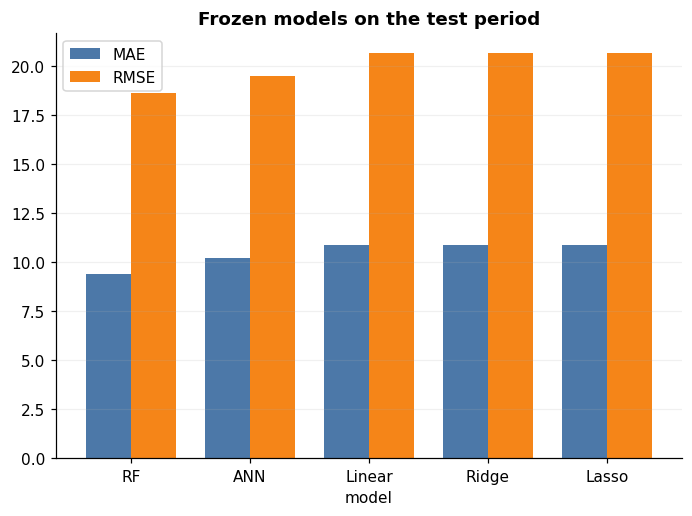

In [122]:
best=validation.loc[validation.groupby("family").validation_MAE.idxmin()]
dev=train|valid; test_rows=[]; test_predictions={}; fitted={}
for _,r in best.iterrows():
    model,cols=candidates[r.setting]; model.fit(d.loc[dev,cols],y[dev]); p=np.clip(model.predict(d.loc[test,cols]),0,None)
    fitted[r.family]=(model,cols); test_predictions[r.family]=p; test_rows.append({"model":r.family,**metrics(y[test],p)})
test_results=pd.DataFrame(test_rows).sort_values("MAE"); display(best[["family","setting","validation_MAE"]]); display(test_results)
test_results.set_index("model")[["MAE","RMSE"]].plot.bar(rot=0,width=.76,color=["#4C78A8","#F58518"],title="Frozen models on the test period"); plt.grid(axis="y",alpha=.18); plt.tight_layout()

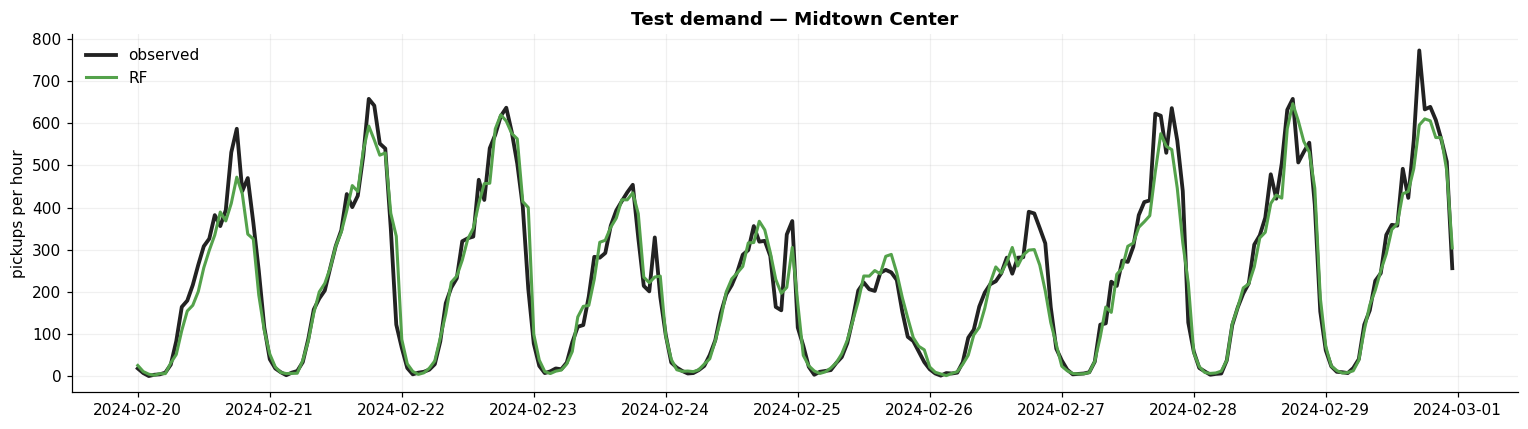

In [123]:
best_name=test_results.iloc[0].model; plot_zone=d.loc[test].groupby("zone_name").pickups.sum().idxmax(); mask=d.loc[test,"zone_name"].eq(plot_zone).to_numpy()
plt.figure(figsize=(14,4)); plt.plot(d.loc[test].loc[mask,"time"],y[test][mask],label="observed",lw=2.5,color="#222222"); plt.plot(d.loc[test].loc[mask,"time"],test_predictions[best_name][mask],label=best_name,color=FAMILY_COLORS[best_name],lw=2)
plt.title(f"Test demand — {plot_zone}"); plt.ylabel("pickups per hour"); plt.legend(frameon=False); plt.grid(alpha=.18); plt.tight_layout()

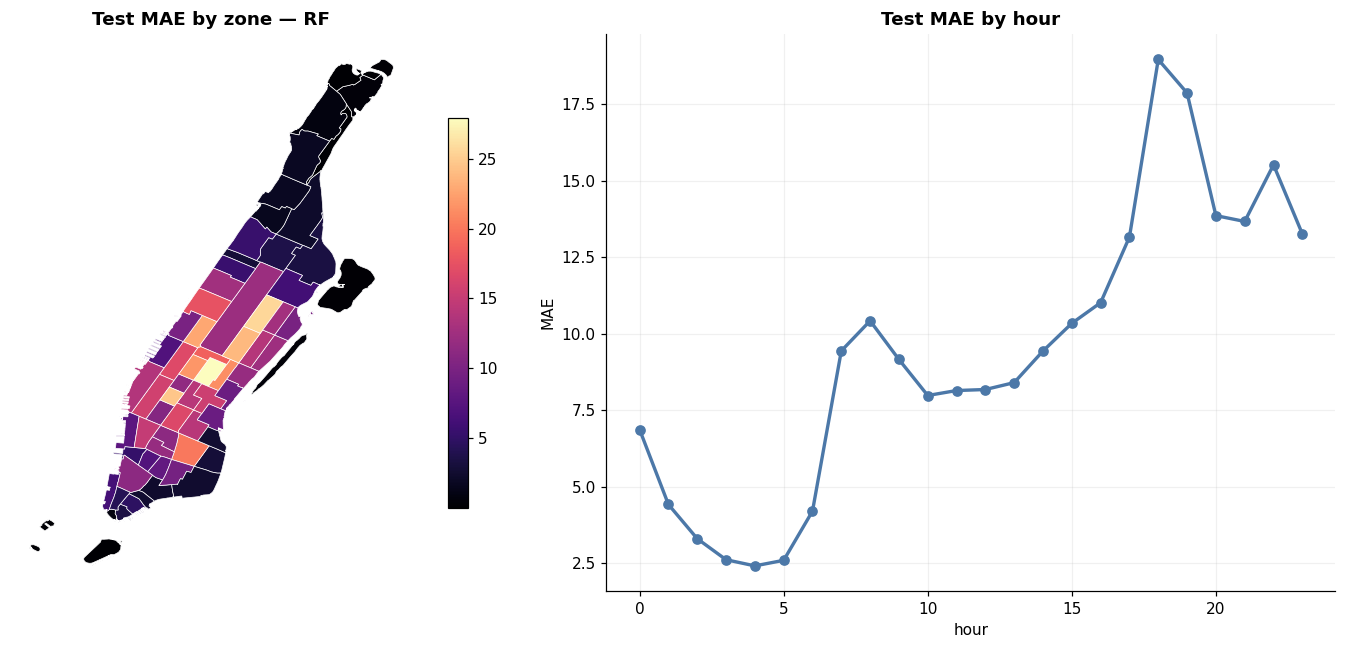

In [124]:
err=pd.DataFrame({"zone_id":d.loc[test,"zone_id"],"ae":np.abs(y[test]-test_predictions[best_name])}).groupby("zone_id").ae.mean()
fig,ax=plt.subplots(1,2,figsize=(14,6)); zone_map(err,f"Test MAE by zone — {best_name}",cmap="magma",ax=ax[0])
hour_err=pd.DataFrame({"hour":d.loc[test,"time"].dt.hour,"ae":np.abs(y[test]-test_predictions[best_name])}).groupby("hour").ae.mean()
ax[1].plot(hour_err.index,hour_err.values,marker="o",color="#4C78A8",lw=2.2); ax[1].set(title="Test MAE by hour",xlabel="hour",ylabel="MAE"); ax[1].grid(alpha=.18); plt.tight_layout()

## 5. What did the random forest use?

Impurity-based feature importance is useful for model inspection, but it is not a causal effect. Correlated lags may divide importance between themselves, and a feature can be predictive without causing demand.

Takeaway: recent observations describe the current state; daily and weekly lags supply recurring temporal context.


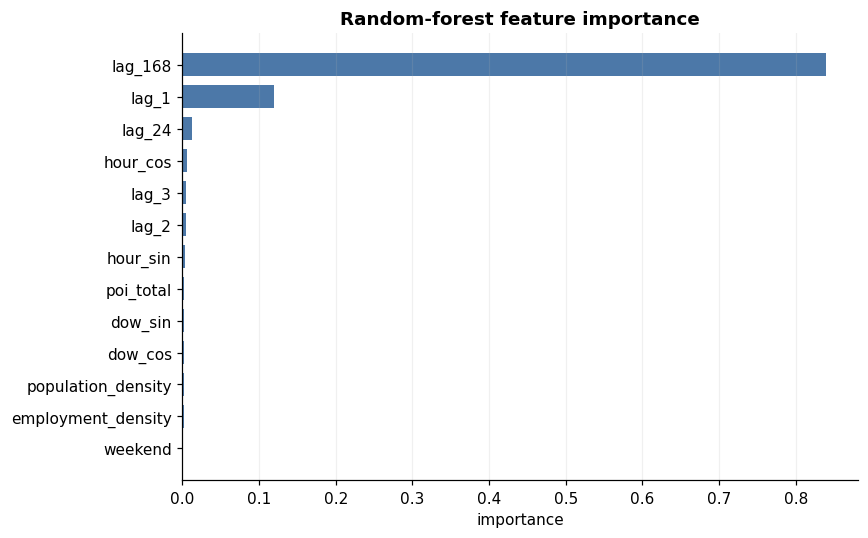

In [125]:
rf,rf_cols=fitted["RF"]
imp=pd.Series(rf.feature_importances_,index=rf_cols).sort_values()
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(imp.index,imp.values,height=.72,color="#4C78A8"); ax.set(xlabel="importance",title="Random-forest feature importance"); ax.grid(axis="x",alpha=.18); plt.tight_layout()
print("Takeaway: recent observations describe the current state; daily and weekly lags supply recurring temporal context.")